
=== Aplicação Meteorológica, a tua tabela é [((2022, 1, 20), 2, 16, 0), ((2022, 1, 21), 1, 13, 0.2), ((2022, 1, 23), 6, 19, 0.6), ((2022, 1, 24), 3, 18, 0.8), ((2022, 2, 20), 6, 19, 0.2), ((2022, 2, 24), 3, 18, 0.2), ((2022, 2, 28), 3, 18, 0.2)] ===
        --> 1 - Mostrar temperatura média de cada dia
        --> 2 - Mostrar temperatura mínima absoluta
        --> 3 - Mostrar amplitude térmica por dia
        --> 4 - Mostrar dia de maior chuva
        --> 5 - Mostrar dias chuvosos acima de p (x precipitação)
        --> 6 - Maior número consecutivo de dias "secos" abaixo de p (x precipitação)
        --> 7 - Guardar tabela num ficheiro
        --> 8 - Carregar tabela de um ficheiro
        --> 9 - Mostrar gráfico
        --> 0 - Sair
Temperatura média de cada dia: [((2022, 1, 20), 9.0), ((2022, 1, 21), 7.0), ((2022, 1, 23), 12.5), ((2022, 1, 24), 10.5), ((2022, 2, 20), 12.5), ((2022, 2, 24), 10.5), ((2022, 2, 28), 10.5)]

=== Aplicação Meteorológica, a tua tabela é [((2022, 1, 20), 2

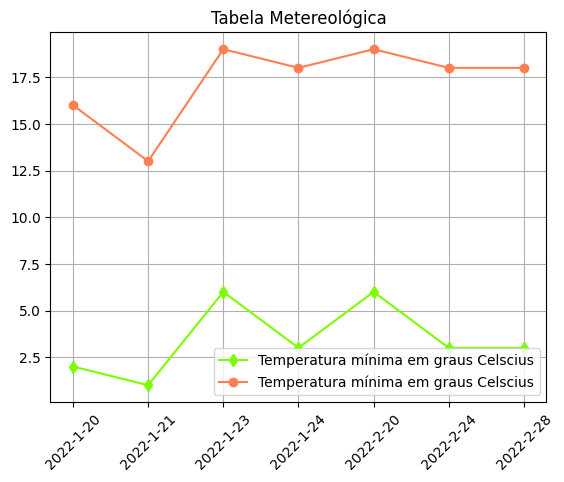


=== Aplicação Meteorológica, a tua tabela é [((2022, 1, 20), 2.0, 16.0, 0.0), ((2022, 1, 21), 1.0, 13.0, 0.2), ((2022, 1, 23), 6.0, 19.0, 0.6), ((2022, 1, 24), 3.0, 18.0, 0.8), ((2022, 2, 20), 6.0, 19.0, 0.2), ((2022, 2, 24), 3.0, 18.0, 0.2), ((2022, 2, 28), 3.0, 18.0, 0.2)] ===
        --> 1 - Mostrar temperatura média de cada dia
        --> 2 - Mostrar temperatura mínima absoluta
        --> 3 - Mostrar amplitude térmica por dia
        --> 4 - Mostrar dia de maior chuva
        --> 5 - Mostrar dias chuvosos acima de p (x precipitação)
        --> 6 - Maior número consecutivo de dias "secos" abaixo de p (x precipitação)
        --> 7 - Guardar tabela num ficheiro
        --> 8 - Carregar tabela de um ficheiro
        --> 9 - Mostrar gráfico
        --> 0 - Sair
A sair...
None


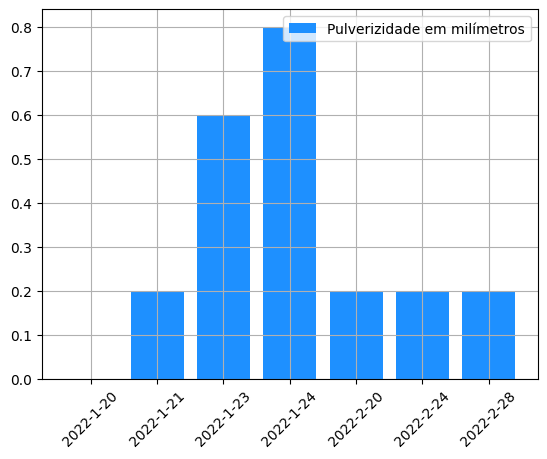

In [1]:
# TabMeteo = [(Data,TempMin,TempMax,Precipitacao)]
    # Data = (Int,Int,Int)
    # TempMin = Float
    # TempMax = Float
    # Precipitacao = Float

from matplotlib import pyplot as plt

tabMeteo1 = [((2022,1,20), 2, 16, 0),((2022,1,21), 1, 13, 0.2), ((2022,1,22), 7, 17, 0.01)]
tabMeteo3 = [((2022,1,20), 2, 16, 0), ((2022,1,21), 1, 13, 0.2), ((2022,1,23), 6, 19, 0.6), ((2022,1,24), 3, 18, 0.8),((2022,2,20), 6, 19, 0.2), ((2022,2,24), 3, 18, 0.2), ((2022,2,28), 3, 18, 0.2)]

def medias(tabMeteo):
    res = []
    for t in tabMeteo:
            data=t[0]
            temperaturaMédia=(t[1]+t[2])/2
            res.append((data,temperaturaMédia))
    return res

def minMin(tabMeteo):
    minima = tabMeteo[0][1]
    for t in tabMeteo:
        if minima > t[1]:
            minima = t[1]

    return minima

def amplTerm(tabMeteo):
    res = []
    for t in tabMeteo:
        ampl = t[2] - t[1]
        res.append((t[0],ampl))
    return res 

def maxChuva(tabMeteo):
    max_prec=tabMeteo[0][3]
    max_data=tabMeteo[0][0]
    for t in tabMeteo:
        if max_prec < t[3]:
            max_prec=t[3]
            max_data=t[0]
    return (max_data, max_prec)


def diasChuvosos(tabMeteo, p):
    l=[]
    for t in tabMeteo:
        if p < t[3]:
            l.append((t[0],t[3]))
    return l

def maxPeriodoCalor(tabMeteo, p):
    max_dias=0
    res=0
    for t in tabMeteo:
        if p > t[3]:
            res+=1
            if res > max_dias:
                max_dias=res
        else:
            res=0
    return max_dias

def guardaTabMeteo(t, fnome): # t - a tabela ; fnome - o ficheiro
    file=open(fnome, "w")
    for d,tmin,tmax,prec in t:
        ano,mes,dia=d
        file.write(f"{ano}-{mes}-{dia};{tmin};{tmax};{prec}\n")
    file.close()
    return

def carregaTabMeteo(fnome): #basicamente é fazer o inverso de há pouco:)
    res = []
    file=open(fnome,"r")
    for line in file:
        #line=line[:-1]
        line=line.strip()
        campos=line.split(";")
        data,tmin, tmax,prec=campos
        ano,mes,dia=data.split("-")
        tuplo=((int(ano),int(mes),int(dia)),float(tmin),float(tmax),float(prec))
        res.append(tuplo)
    file.close()
    return res

tabMeteo2 = carregaTabMeteo("meteorologia.txt")

def grafTabMeteo(t):
    x = [f"{data[0]}-{data[1]}-{data[2]}" for data,tmin,tmax,prec in t] #data *_
    ytmin = [tmin for data,tmin,tmax,prec in t]
    ytmax = [tmax for data,tmin,tmax,prec in t]

    yprec=[prec for *_,prec in t]
    plt.plot(x,ytmin, label="Temperatura mínima em graus Celscius", color="lawngreen", marker="d")
    plt.plot(x,ytmax, label="Temperatura mínima em graus Celscius", color="coral", marker="o")
    plt.legend()
    plt.title("Tabela Metereológica")
    plt.grid()
    plt.xticks(rotation=45)
    plt.show()

    plt.bar(x,yprec, label="Pulverizidade em milímetros", color="dodgerblue")
    plt.legend()
    plt.grid()
    plt.xticks(rotation=45)
    plt.show
    return

def main():
    tabMeteo3 = [
        ((2022,1,20), 2, 16, 0),
        ((2022,1,21), 1, 13, 0.2),
        ((2022,1,23), 6, 19, 0.6),
        ((2022,1,24), 3, 18, 0.8),
        ((2022,2,20), 6, 19, 0.2),
        ((2022,2,24), 3, 18, 0.2),
        ((2022,2,28), 3, 18, 0.2)
    ]
    opcao=-1
    while opcao!=0:
        print(f"""\n=== Aplicação Meteorológica, a tua tabela é {tabMeteo3} ===
        --> 1 - Mostrar temperatura média de cada dia
        --> 2 - Mostrar temperatura mínima absoluta
        --> 3 - Mostrar amplitude térmica por dia
        --> 4 - Mostrar dia de maior chuva
        --> 5 - Mostrar dias chuvosos acima de p (x precipitação)
        --> 6 - Maior número consecutivo de dias "secos" abaixo de p (x precipitação)
        --> 7 - Guardar tabela num ficheiro
        --> 8 - Carregar tabela de um ficheiro
        --> 9 - Mostrar gráfico
        --> 0 - Sair""")

        opcao=int(input("Escolha uma opção: "))

        if opcao == 1:
            print("Temperatura média de cada dia:", medias(tabMeteo3))
        elif opcao == 2:
            print("Temperatura mínima absoluta:", minMin(tabMeteo3))
        elif opcao == 3:
            print("Amplitude térmica:", amplTerm(tabMeteo3))
        elif opcao == 4:
            print("Dia de maior chuva:", maxChuva(tabMeteo3))
        elif opcao == 5:
            p = float(input("Valor mínimo de precipitação: "))
            print("Dias chuvosos:", diasChuvosos(tabMeteo3, p))
        elif opcao == 6:
            p = float(input("Valor máximo de precipitação para considerar 'seco': "))
            print("Maior sequência de dias secos:", maxPeriodoCalor(tabMeteo3, p))
        elif opcao == 7:
            nome = input("Nome do ficheiro: ")
            guardaTabMeteo(tabMeteo3, nome)
            print("Tabela guardada com sucesso!")
        elif opcao == 8:
            nome = input("Nome do ficheiro: ")
            tabMeteo3 = carregaTabMeteo(nome)
            print(tabMeteo3)
            print("Tabela carregada com sucesso!")
        elif opcao == 9:
            grafTabMeteo(tabMeteo3)
        elif opcao == 0:
            print("A sair...")
        else:
            print("Opção inválida. Tente novamente.")

print(main())

